# 5. Serving and latency

The model scored one transaction at a time by a service that keeps a time-sorted neighbour index. Numbers come from one machine replaying historical data; they are not a production claim, and the 100 ms budget is an illustrative assumption.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
import json
lat = load_results('latency.csv')
meta = json.loads((out_dir() / 'latency_meta.json').read_text())
print('FIXTURE RESULTS - not findings' if meta['fixture'] else 'real data')
print('hardware:', meta['hardware'])
print('parity with the offline scores:', meta['parity'])

real data
hardware: {'platform': 'Windows-11-10.0.26300-SP0', 'processor': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'cpu_count': 16, 'python': '3.14.7', 'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 3070 Ti Laptop GPU'}
parity with the offline scores: {'checked': True, 'max_abs_diff': 0.0, 'n_rows': 200, 'reason': ''}


In [2]:
cols = ['model', 'device', 'mode', 'batch_size', 'concurrency', 'p50_ms', 'p95_ms', 'p99_ms', 'throughput_rps', 'p99_within_budget']
aggregate_latency(lat)[[c for c in cols if c not in ('p99_within_budget',)] + ['p50_min_ms', 'p50_max_ms', 'repeats']].round(2)

,model,device,mode,batch_size,concurrency,p50_ms,p95_ms,p99_ms,throughput_rps,p50_min_ms,p50_max_ms,repeats
0,gnn,cpu,inprocess,1,1,18.99,21.23,22.84,53.59,18.98,18.99,3
1,gnn,cpu,inprocess,8,1,25.45,28.80,31.78,315.98,25.42,25.88,3
2,gnn,cpu,inprocess,32,1,46.26,50.65,62.69,700.65,44.99,46.40,3
3,gnn,cpu,inprocess,128,1,133.84,153.82,158.28,943.42,133.70,140.34,3
4,gnn,cuda,inprocess,1,1,26.00,33.57,37.74,37.57,25.85,26.07,3
5,gnn,cuda,inprocess,8,1,32.78,40.24,44.64,238.36,32.50,33.25,3
6,gnn,cuda,inprocess,32,1,47.13,54.54,68.84,664.64,46.66,47.91,3
7,gnn,cuda,inprocess,128,1,114.85,134.94,140.71,1078.23,114.51,116.29,3
8,gnn,cpu,http,1,1,20.74,24.94,34.00,47.07,20.57,21.81,3
9,gnn,cpu,http,32,1,66.89,74.65,81.55,470.13,60.81,76.08,3


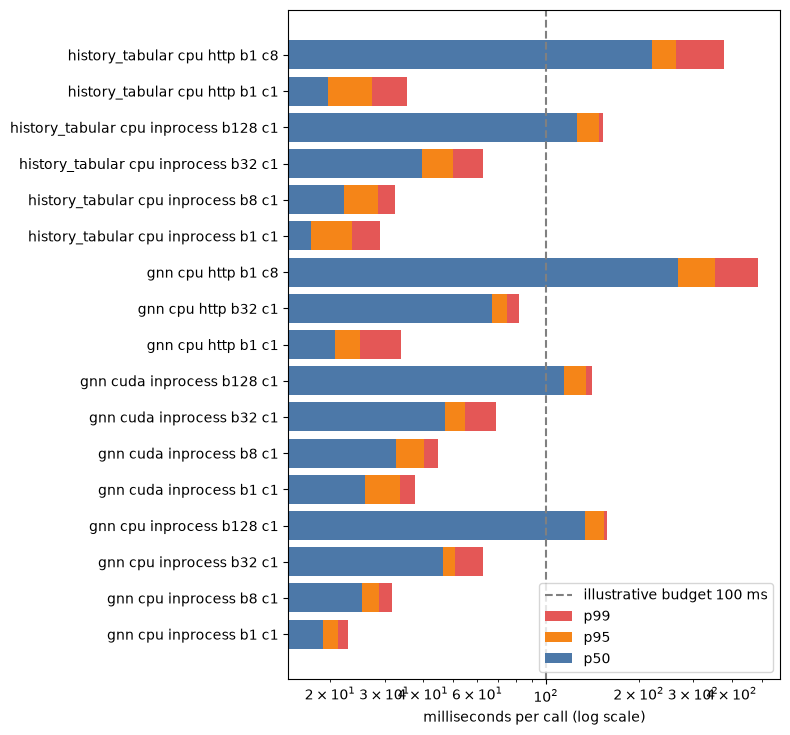

In [3]:
plot_latency(lat, meta['budget_ms']);

## Where the time goes (batch size 1)

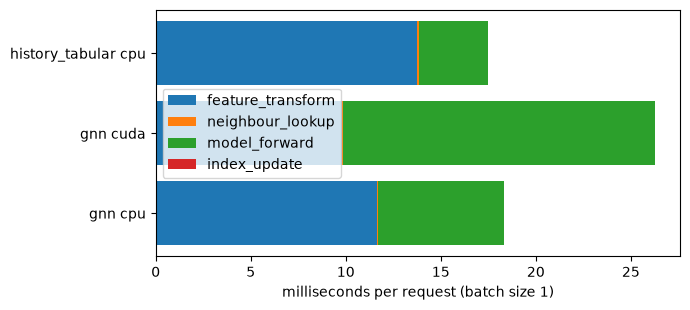

In [4]:
plot_breakdown(lat);

## Stock sampler versus the custom index

The `stock_neighbor_loader` row is the cost of sampling the neighbourhood alone with PyG's loader built per request; compare it with the `neighbour_lookup` share above.

In [5]:
aggregate_latency(lat[lat['mode'] == 'lookup_only'])[['model', 'p50_ms', 'p95_ms', 'p99_ms', 'repeats']].round(2)

,model,p50_ms,p95_ms,p99_ms,repeats
0,stock_neighbor_loader,316.66,354.28,433.26,3


Index size and the concurrency caveat: the metadata printed above lists the indexed transactions and the serialised index size. Scoring is serialised by one lock, so extra clients do not add throughput; the multi-client row shows the queueing cost.